In [ ]:
# ---> Smartcart_Clustering_System

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.head(10)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0
5,7446,1967,Master,Together,62513.0,0,1,09-09-2013,16,520,...,0,42,14,2,6,4,10,6,0,0
6,965,1971,Graduation,Divorced,55635.0,0,1,13-11-2012,34,235,...,50,49,27,4,7,3,7,6,0,0
7,6177,1985,PhD,Married,33454.0,1,0,08-05-2013,32,76,...,3,1,23,2,4,0,4,8,0,0
8,4855,1974,PhD,Together,30351.0,1,0,06-06-2013,19,14,...,3,3,2,1,3,0,2,9,0,1
9,5899,1950,PhD,Together,5648.0,1,1,13-03-2014,68,28,...,1,1,13,1,1,0,0,20,0,0


In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# _________________________________________________________________________
# ------> Data preprocessing

#### 1. handle missing values or null values

In [5]:
# 1. handle missing values or null values
df["Income"] = df["Income"].fillna(df["Income"].median())

In [6]:
df
df.isnull().sum()

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [7]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='object')

# _______________________________________________________________
## ----->2. Feature engineering


### 1. Year_Birth → Age

Convert the customer's birth year into their age.

Formula:

\\[ \text{Age} = \text{Reference Year} - \text{Year\\\_Birth} \\]

### 2. Dt_Customer → Customer Tenure (Days)

`Dt_Customer` represents the date when a customer joined SmartCart.

- Convert the date into a proper date format (`DD-MM-YYYY`).
- Calculate how many days have passed since the customer joined, using the latest joining date in the dataset as the reference date.

Formula:

\\[ \text{Customer Tenure (Days)}=\text{Latest Date}-\text{Dt\\\_Customer} \\]

Example: If the latest date is 7 January 2010:

| Joining Date   | Customer Tenure (Days) |
| -------------- | ---------------------- |
| 1 January 2010 | 6                      |
| 5 January 2010 | 2                      |
| 7 January 2010 | 0                      |



In [8]:
# AGE 
df["Age"] = 2026-df["Year_Birth"]

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


In [10]:
# CUSTOMER JOINING DATE

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst = True)   # pandas support date format ----> (month-day-year),, so use dayfirt=true

## select reference date 
reference_date = df["Dt_Customer"].max()


df["Customer_Tenure_Days"] = ( reference_date - df["Dt_Customer"]).dt.days

In [11]:
# spinding ----> MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds

df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]


In [12]:
#  CHILDREN

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [13]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [14]:
# EDUCATION

df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [15]:
# convert these in # Undergraduate, Graduate, Postgraduate  

df["Education"].value_counts()

df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate", "PhD": "Postgraduate"
})

In [16]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [17]:
# Marital Status

In [18]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [19]:
# converting these in "Alone" and "Partner"

df["Living_With"] = df["Marital_Status"]. replace({
    "Married": "Partner", "Together": "Partner",
    "Single": "Alone", "Divorced": "Alone",
    "Widow": "Alone", "Absurd": "Alone", "YOLO": "Alone"

})

In [20]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

In [21]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,Postgraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


### -----> 3. Drop Columns

In [22]:
cols = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
spending_cols = ['MntWines', 'MntFruits','MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

tot_cols_drop = cols + spending_cols

df_cleaned = df.drop(columns = tot_cols_drop)

In [23]:
print(df.shape)
print("no. of cols after removing", end =" ")
print(df_cleaned.shape)


(2240, 27)
no. of cols after removing (2240, 15)


In [24]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


# _______________________________________________________
# -----> OUTLIERS

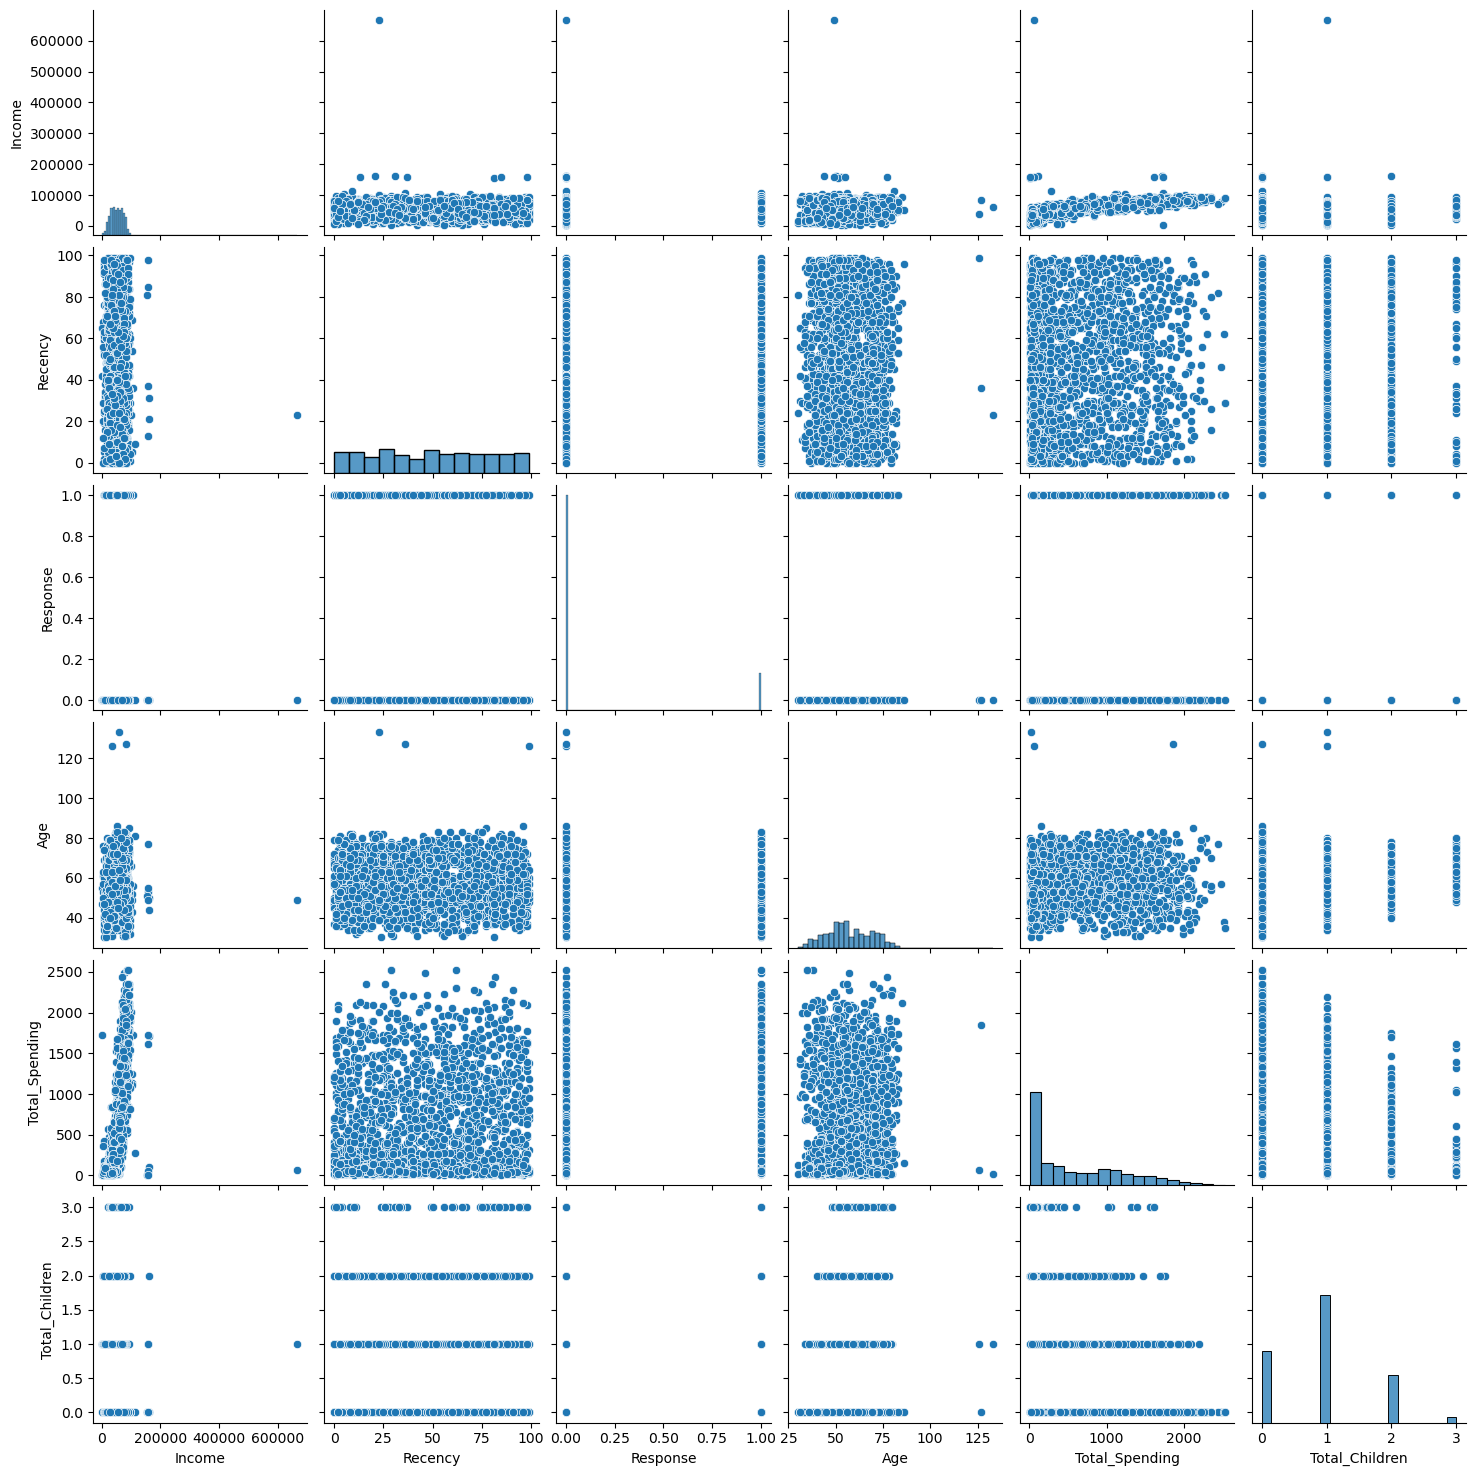

In [25]:
# visualize outliers
cols = ["Income", "Recency", "Response", "Age", "Total_Spending", "Total_Children"]

# relative plots of some features- pair plots  --> pair plot is the plot in which relate n features/cols and make n^2 no. of scatter plot in a one figure.
sns.pairplot(df_cleaned[cols])

In [26]:
# remove outliers

print("data size with outliers:", len(df_cleaned))

df_cleaned = df_cleaned[ (df_cleaned["Age"] < 90) ]
df_cleaned = df_cleaned[ (df_cleaned["Income"] < 600_000) ]

print("data size without some outliers:", len(df_cleaned))


data size with outliers: 2240
data size without some outliers: 2236


#### To show the relation PLOT HEATMAP

In [27]:
corr = df_cleaned.corr(numeric_only = True)

<Axes: >

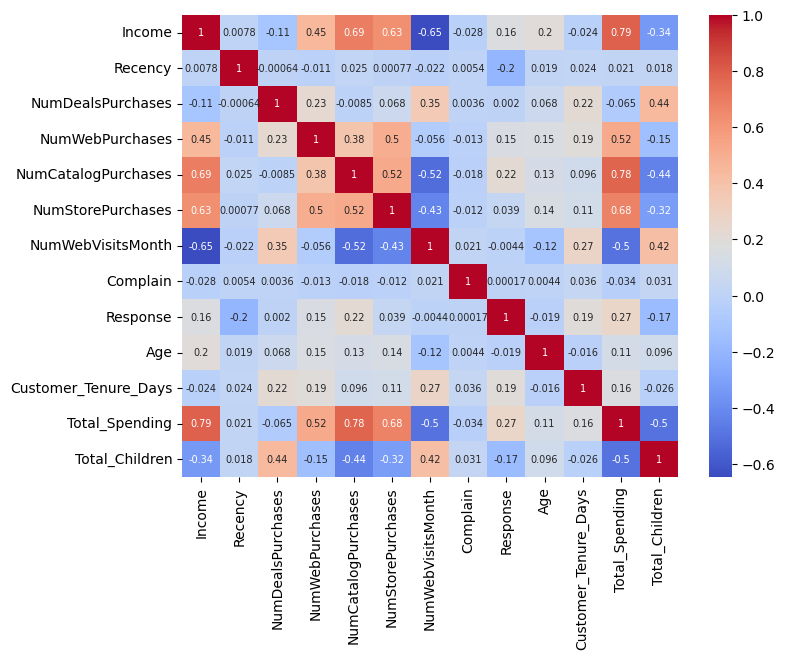

In [28]:
plt.figure(figsize = (8, 6))

sns.heatmap(
    corr,
    annot = True,
    annot_kws={"size": 7},
    cmap = "coolwarm"
)

### Heatmap Observations

imp point's/relation drived from using heatmap

- 0.79: Income ↔ Total Spending
- 0.67: Income ↔ Catalog Purchases
- 0.63: Income ↔ Store Purchases
- -0.65: Income ↔ Number of Web Visits
- 0.78: Spending → Catalog Purchases
- 0.68: Spending → Store Purchases

In [29]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


# ___________________________________________________________________________
## 3. Encoding

In [30]:
from sklearn.preprocessing import OneHotEncoder

In [31]:
ohe = OneHotEncoder()

cat_cols = ["Education", "Living_With"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [32]:
enc_df = pd.DataFrame(enc_cols.toarray(), columns = ohe.get_feature_names_out(cat_cols), index = df_cleaned.index)

In [33]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols),enc_df], axis = 1)

In [34]:
df_encoded.shape

(2236, 18)

In [35]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


# _____________________________________________________________________
# SCALING

In [36]:
from sklearn.preprocessing import StandardScaler

In [37]:
X = df_encoded

In [38]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [39]:
# Visualize

In [40]:
X_scaled.shape

(2236, 18)

In [41]:
# Principal component analysis (PCA) - it reduce the dimensions/features
from sklearn.decomposition import PCA

pca = PCA(
    n_components = 3   # no. of clusters form
)

x_pca = pca.fit_transform(X_scaled)

In [42]:
# variance
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

D:\anaconda\Lib\site-packages\matplotlib\collections.py:999: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


Text(0.5, 0.92, '3d projection')

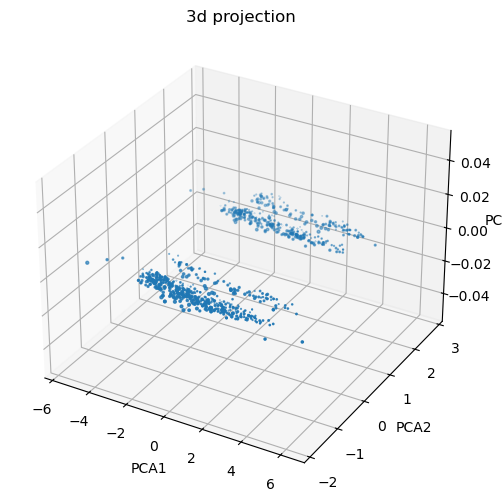

In [43]:
# plot
fig = plt.figure(figsize = (8,6))

ax = fig.add_subplot(111, projection = "3d")

plt.scatter(x_pca[:, 0] ,x_pca[:, 1] , x_pca[:,2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3d projection")

# ________________________________________________________________________________________________________________________________________
# Analyze K value

In [44]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters = k , random_state = 42)
    kmeans.fit_predict(x_pca)
    wcss.append(kmeans.inertia_)

In [45]:
kl = KneeLocator(
    range(1, 11),
    wcss,
    curve="convex",
    direction="decreasing"
)

print("Optimal K:", kl.elbow)

Optimal K: 4


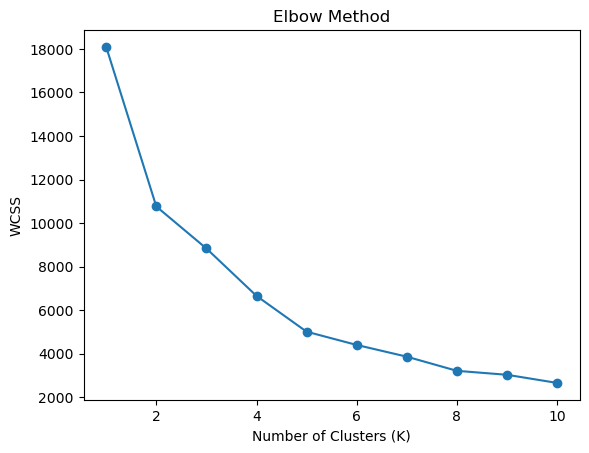

In [46]:
# plot

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()


# ________________________________________________________________________________________________________________________
## Silhouette Score

In [47]:
from sklearn.metrics import silhouette_score

Text(0, 0.5, 'Silhouette score')

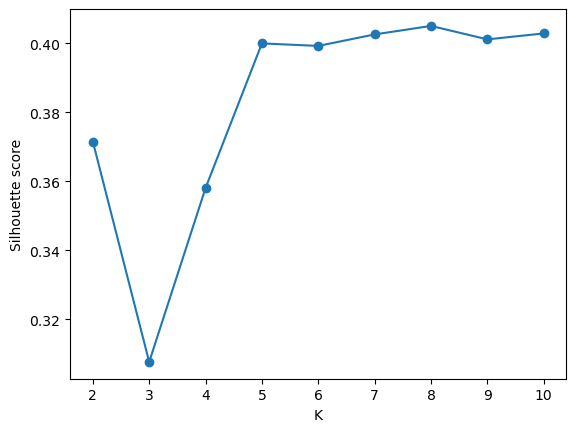

In [48]:
scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters = k , random_state=42)
    labels = kmeans.fit_predict(x_pca)
    score = silhouette_score(x_pca , labels)
    scores.append(score)

# plot
plt.plot(range(2, 11), scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette score")

Text(0, 0.5, 'Silhouette score')

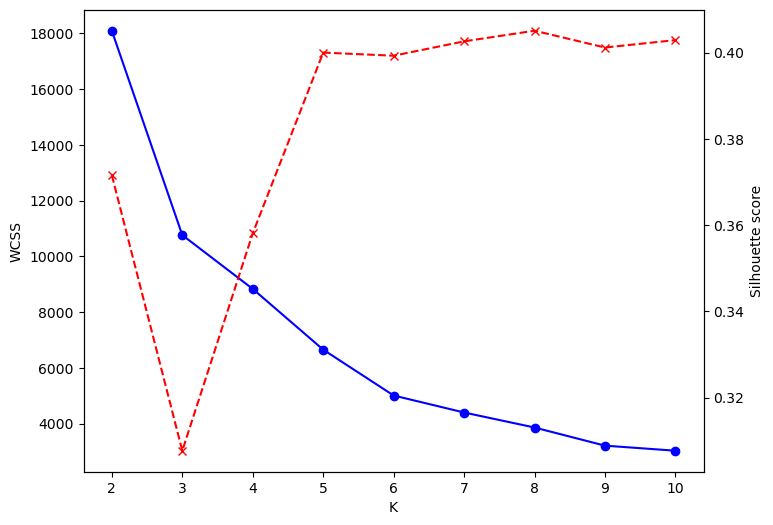

In [49]:
# combined plot

k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(k_range, wcss[: len(k_range)], marker="o", color="blue")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2= ax1.twinx()
ax2.plot(k_range, scores [: len(k_range)], marker="x", color="red", linestyle="--")
ax2.set_ylabel("Silhouette score")

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Clustering

In [50]:
# K_means

kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans. fit_predict(x_pca)

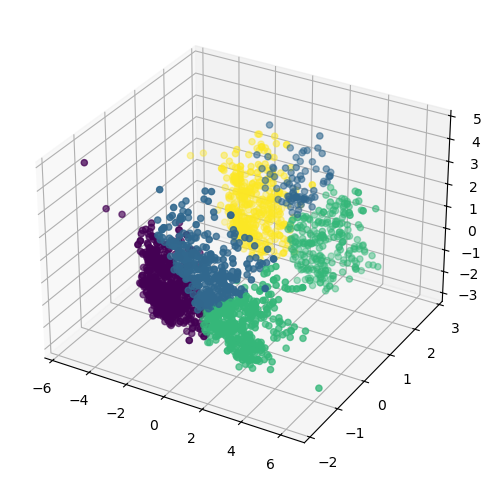

In [51]:
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(x_pca[:, 0], x_pca[:, 1], x_pca[:, 2], c=labels_kmeans)

In [52]:
# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

agg_clf = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg_clf.fit_predict(x_pca)

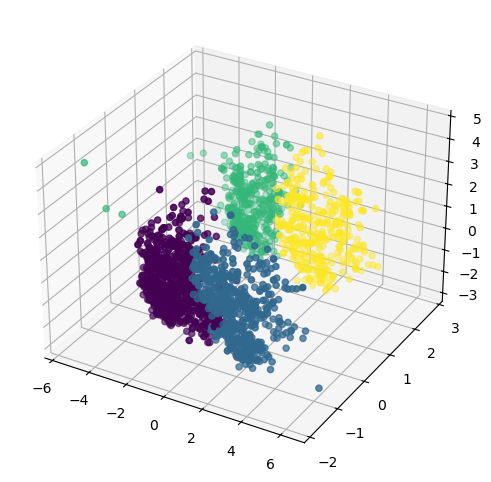

In [53]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x_pca[:, 0], x_pca[:, 1], x_pca[:, 2], c=labels_agg)

# ________________________________________________________________________________________________________________________________________
## Characterization of Clusters
### Characterization of clusters is the process of describing and understanding the main features, properties, and patterns of each cluster formed by a clustering algorithm.

In [54]:
# df_cleaned["cluster"] = labels_agg


X["cluster"] = labels_agg

In [55]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

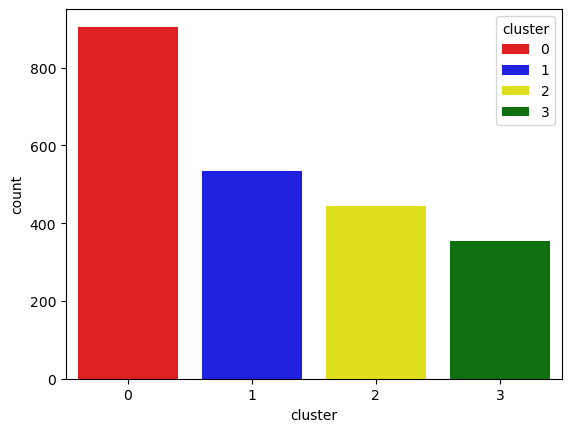

In [56]:
pal = ["red", "blue", "yellow", "green"]

sns.countplot(
    x= X["cluster"],
    palette = pal,
    hue = X["cluster"]
)

<Axes: xlabel='Total_Spending', ylabel='Income'>

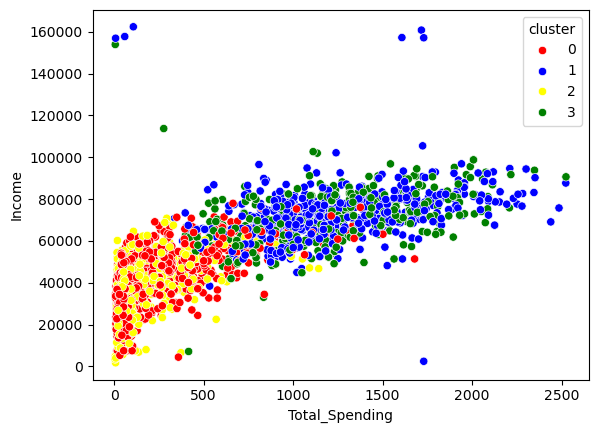

In [58]:
# check for income & Spending patterns because they have high relation

sns.scatterplot(
    x = X["Total_Spending"],
    y=df_cleaned["Income"],
    palette = pal,
    hue = X["cluster"]
)

### Cluster Characterization

- Cluster 0 (Red): Low / moderate income, low / moderate spending.
- Cluster 1 (Blue): High income, high spending.
- Cluster 2 (Yellow): Low income, low spending.
- Cluster 3 (Green): Moderate–high income, high spending.

In [62]:
# Cluster Summary

cluster_summary = X.groupby("cluster").mean()

print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
cluster         

### ---> cluster summary

C0 – Family Shoppers

- More children, poor response, partnered.
- Web visits ↑; web, catalog & store purchases ↓.
- Target: Discount campaigns.

C1 – Loyalty Programs

- Fewer children, slightly higher age, partnered.
- Any response; web purchases ↓, store & catalog purchases ↑.
- Target: Loyalty programs.

C2 – Digital Browsers

- More children, any relationship status, alone.
- Web visits ↑; web, catalog & store purchases ↓.
- Target: Sales through web discounts and digital campaigns.

C3 – Best ROI (High-Value Singles)

- Fewer children, slightly higher age, best response, alone.
- Web visits ↓; store & catalog purchases ↑.
- Target: Premium services and high-value offers.